
=== EXERCISE 3.1: Alpha-particle energies ===
Decay energy Q0: 5.63781 MeV
Alpha energy T_0: 5.54423 MeV
Alpha energy T_1: 5.51158 MeV
Alpha energy T_2: 5.48567 MeV
Alpha energy T_3: 5.44297 MeV
Alpha energy T_4: 5.38835 MeV
Mean energy T_m: 5.47880 MeV
Mean CM energy T_m,c: 5.26279 MeV
Experimental source energy: 3.650 MeV

=== EXERCISE 3.2: Central collision ===
Closest approach D: 63.601 fm
Cross section at 180°: 2426.469 mbarn/sr

=== EXERCISE 3.3: Scattering geometry ===
x = 50 mm:
  Scattering angle: 45.115°
  Impact parameter: 75.031 fm
x = 150 mm:
  Scattering angle: 28.013°
  Impact parameter: 124.946 fm

Validity of Rutherford scattering:
Sum of nuclear radii: 9.628 fm
High-energy limit (lab): 24.111 MeV
Low-energy limit (CM relative): 0.340 MeV
Experimental relative energy: 3.577 MeV

=== EXERCISE 3.4.1: Energy loss in gold ===
Stopping power: 88.312 eV/(10^15 atoms/cm²)
Stopping power: 521.923 keV/µm
Central foil energy loss: 521.923 keV
Detector window energy loss: 65.240

/var/folders/1c/87dvwcs50pjgfyfjxl387jhr0000gn/T/ipykernel_42265/2322899272.py:220: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


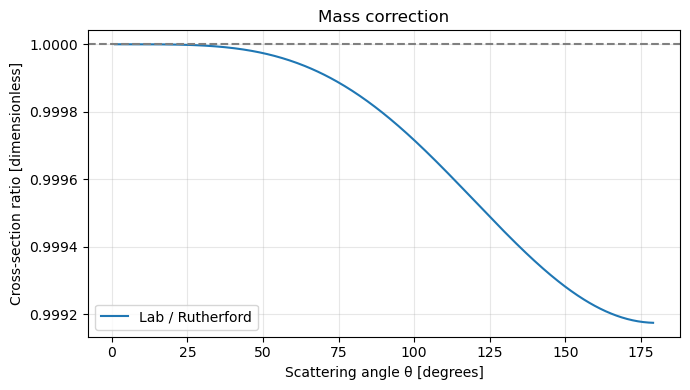


=== EXERCISE 3.5.1: Mass correction ===
Maximum correction: 0.0825 %


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
# Atomic masses [u]
m_Am = 241.056822944
m_Np = 237.048167253
m_He = 4.002603250
m_alpha = 4.001487900
m_Au = 196.96656879
u_to_MeV = 931.49432
# Rutherford parameters
Z1, Z2 = 2, 79
E0 = 3.65                    # MeV
xi2 = 1.44                  # eV nm
K1 = m_alpha / m_Au
# Experimental geometry
delta = 74.5
RA, R1, R2 = 25, 23, 27
AD = 50                     # mm²
RD = np.sqrt(AD / np.pi)    # mm
r_det = RD #mm
# Gold layers
d_foil = 1.0                # µm, approximate
rho_Au = 19.2               # g/cm³
d_window = 240e-6 / rho_Au * 1e4  # µm
N_Au = 5.91e22              # atoms/cm³


# ============================================================
# GENERAL FUNCTIONS
# ============================================================

def scattering_angle(x, R=RA, r_det=0):
    """Scattering angle [rad], distances in mm."""
    return np.arctan(R/delta) + np.arctan((R-r_det)/x)

def stopping_power(E, Z, EB, K):
    """Stopping power [eV/(10^15 atoms/cm²)]."""
    return 3.80/E * Z * np.log(548.58*E/EB - K)

def sigma_rutherford(theta):
    """Rutherford differential cross section [mbarn/sr]."""
    return 1.296 * (Z1*Z2/E0)**2 / np.sin(theta/2)**4

def sigma_lab(theta):
    """Lab-frame differential cross section [mbarn/sr]."""
    q = np.sqrt(1 - K1**2*np.sin(theta)**2)
    return (1.296 * (Z1*Z2/E0)**2
            * 4*(np.cos(theta)+q)**2
            / (np.sin(theta)**4*q))

def kinematic_factor(theta):
    """Fraction of alpha energy remaining after scattering."""
    return ((K1*np.cos(theta)
             + np.sqrt(1-K1**2*np.sin(theta)**2))
            / (1+K1))**2

# ============================================================
# EXERCISE 3.1 - KINETIC ENERGY OF ALPHA PARTICLES
# ============================================================

E_A = np.array([0, 33.20, 59.54, 102.96, 158.51])  # keV
I_alpha = np.array([0.34, 0.22, 84.5, 13.0, 1.6])  # %

Q0 = (m_Am - m_Np - m_He) * u_to_MeV
T_alpha = (Q0 - E_A/1000) / (1 + m_alpha/m_Np)

T_mean = np.average(T_alpha, weights=I_alpha)
T_mc = T_mean / (1 + K1)**2

print("\n=== EXERCISE 3.1: Alpha-particle energies ===")
print(f"Decay energy Q0: {Q0:.5f} MeV")

for i, T in enumerate(T_alpha):
    print(f"Alpha energy T_{i}: {T:.5f} MeV")

print(f"Mean energy T_m: {T_mean:.5f} MeV")
print(f"Mean CM energy T_m,c: {T_mc:.5f} MeV")
print(f"Experimental source energy: {E0:.3f} MeV")


# ============================================================
# EXERCISE 3.2 - CLOSEST APPROACH AND CROSS SECTION
# ============================================================

D = Z1*Z2*xi2*(1+K1)/(E0*1e6)  # nm

theta_180 = np.pi

# Equation 17: mass-corrected approximation
sigma_180 = sigma_rutherford(theta_180) * (
    1 - 2*K1**2
)

print("\n=== EXERCISE 3.2: Central collision ===")
print(f"Closest approach D: {D*1e6:.3f} fm")
print(f"Cross section at 180°: {sigma_180:.3f} mbarn/sr")


# ============================================================
# EXERCISE 3.3 - ANGLES, IMPACT PARAMETERS AND VALIDITY
# ============================================================

print("\n=== EXERCISE 3.3: Scattering geometry ===")

for x in [50, 150]:
    theta = scattering_angle(x)
    b = Z1*Z2*xi2/(2*E0*np.tan(theta/2))  # fm

    print(f"x = {x} mm:")
    print(f"  Scattering angle: {np.degrees(theta):.3f}°")
    print(f"  Impact parameter: {b:.3f} fm")

# Nuclear-force limit
r0 = 1.3  # fm
R_sum = r0 * (197**(1/3) + 4**(1/3))
E_high = Z1*Z2*xi2*(1+K1)/R_sum  # MeV

# Electron-screening limit
a0 = 0.0529  # nm
E_low = Z1*Z2**2*xi2/a0/1e6  # MeV, relative energy
E_relative = E0/(1+K1)

print("\nValidity of Rutherford scattering:")
print(f"Sum of nuclear radii: {R_sum:.3f} fm")
print(f"High-energy limit (lab): {E_high:.3f} MeV")
print(f"Low-energy limit (CM relative): {E_low:.3f} MeV")
print(f"Experimental relative energy: {E_relative:.3f} MeV")


# ============================================================
# EXERCISE 3.4.1 - STOPPING POWER IN GOLD
# ============================================================

epsilon_Au = stopping_power(E0, 79, 1059.81, -1.037)
S_Au = epsilon_Au*N_Au/1e15/1e7  # keV/µm

print("\n=== EXERCISE 3.4.1: Energy loss in gold ===")
print(f"Stopping power: {epsilon_Au:.3f} eV/(10^15 atoms/cm²)")
print(f"Stopping power: {S_Au:.3f} keV/µm")

# Direct beam through central hole
DE_foil = S_Au*d_foil
DE_window = S_Au*d_window
E_detector = E0 - (DE_foil+DE_window)/1000

print(f"Central foil energy loss: {DE_foil:.3f} keV")
print(f"Detector window energy loss: {DE_window:.3f} keV")
print(f"Energy available in silicon: {E_detector:.4f} MeV")

# Extreme geometrical paths at x = 50 mm
def detector_energy(R, r_det, x):
    alpha = np.arctan(R/delta)
    beta = np.arctan((R-r_det)/x)
    theta = alpha + beta

    L_in = d_foil/(2*np.cos(alpha))
    L_out = d_foil/(2*np.cos(beta))
    L_window = d_window/np.cos(beta)

    E_before = E0 - S_Au*L_in/1000
    E_after = E_before*kinematic_factor(theta)

    return E_after - S_Au*(L_out+L_window)/1000

E_min = detector_energy(R2, -RD,50)
E_max = detector_energy(R1, RD,50)

print("\nExtreme paths at detector distance x = 50 mm:")
print(f"Minimum detector energy: {E_min:.4f} MeV")
print(f"Maximum detector energy: {E_max:.4f} MeV")

E_min_w = detector_energy(R2, -RD,150)
E_max_w = detector_energy(R1, RD,150)

print("\nExtreme paths at detector distance x = 150 mm:")
print(f"Minimum detector energy: {E_min_w:.4f} MeV")
print(f"Maximum detector energy: {E_max_w:.4f} MeV")

# ============================================================
# EXERCISE 3.4.2 - STOPPING POWER IN AIR
# ============================================================

epsilon_air = stopping_power(E0, 7.3, 94.22, 0.710)

# Approximate atomic density of air at atmospheric pressure
N_air = 5.0e19  # atoms/cm³

S_air = epsilon_air*N_air/1e15/1e4  # keV/mm

print("\n=== EXERCISE 3.4.2: Energy loss in air ===")
print(f"Stopping power: {epsilon_air:.3f} eV/(10^15 atoms/cm²)")
print(f"At atmospheric pressure: {S_air:.3f} keV/mm")

for pressure in [10, 40]:
    S_p = S_air*pressure/1013.25
    print(f"At {pressure} mbar: {S_p:.4f} keV/mm")


# ============================================================
# EXERCISE 3.5.1 - MASS CORRECTION
# ============================================================

theta = np.radians(np.linspace(1, 179, 500))
mass_ratio = sigma_lab(theta)/sigma_rutherford(theta)

plt.figure(figsize=(7, 4))
plt.plot(np.degrees(theta), mass_ratio,
         label="Lab / Rutherford")
plt.axhline(1, color="gray", linestyle="--")
plt.xlabel("Scattering angle θ [degrees]")
plt.ylabel("Cross-section ratio [dimensionless]")
plt.title("Mass correction")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "mass_correction.pdf",
            bbox_inches="tight")
plt.show()
plt.show()

print("\n=== EXERCISE 3.5.1: Mass correction ===")
print(f"Maximum correction: {np.max(abs(mass_ratio-1))*100:.4f} %")

6.3 Background = 0.01472 +/- 0.00204 1/s

6.2 Peak B = 541.126 +/- 1.558 threshold units; FWHM = 156.444 +/- 2.230 threshold units
    Plateau [125, 300]: slope = -0.007 +/- 0.007 1/(s unit) (6 points)


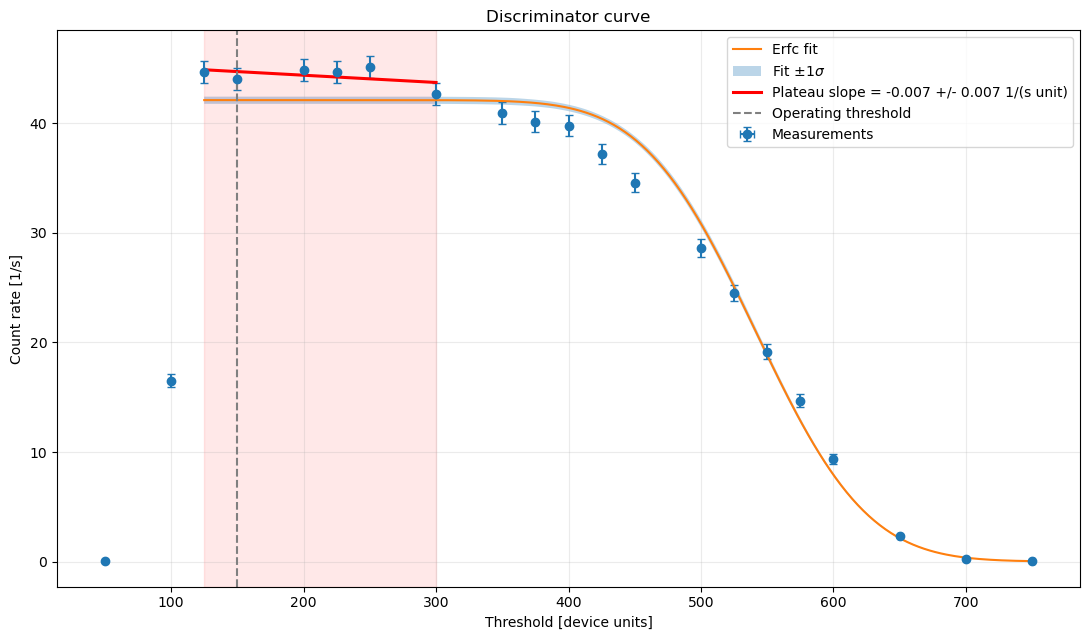

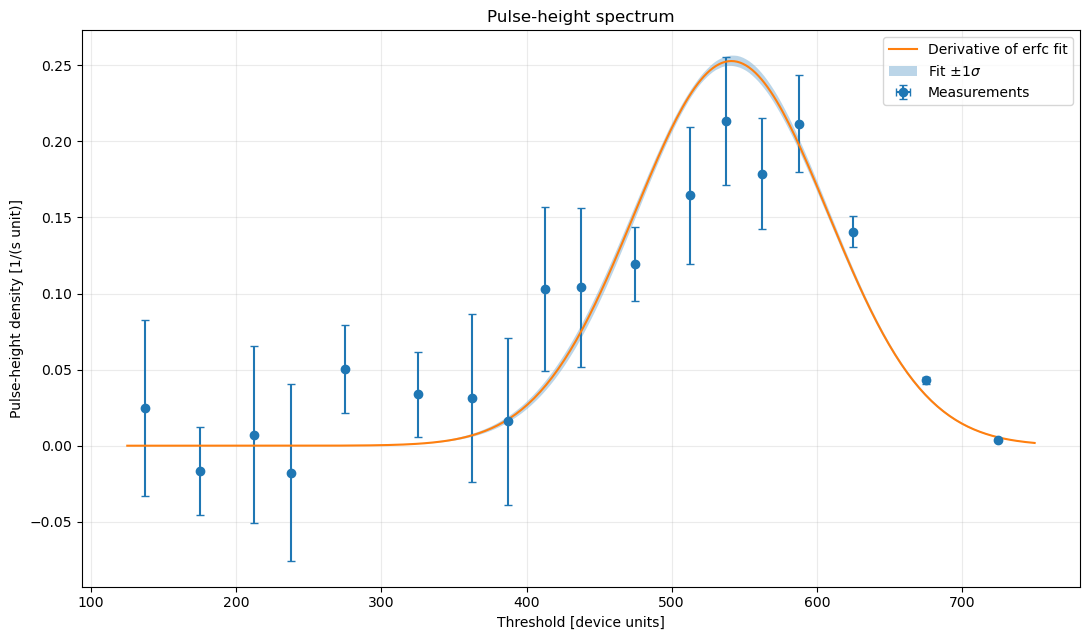


=== DIRECT DETECTOR ENERGY ===
Air energy loss: 0.5883 MeV
Gold foil energy loss: 0.5219 MeV
Detector window loss: 0.0652 MeV
Energy at detector: 2.4746 MeV
Direct count rate: 44.390 +/- 0.299 1/s

=== ENERGY DISTRIBUTION ===
Conversion factor: 0.0050 MeV/mV
Sigma_E: 0.3347 MeV
FWHM: 0.7882 +/- 0.0350 MeV


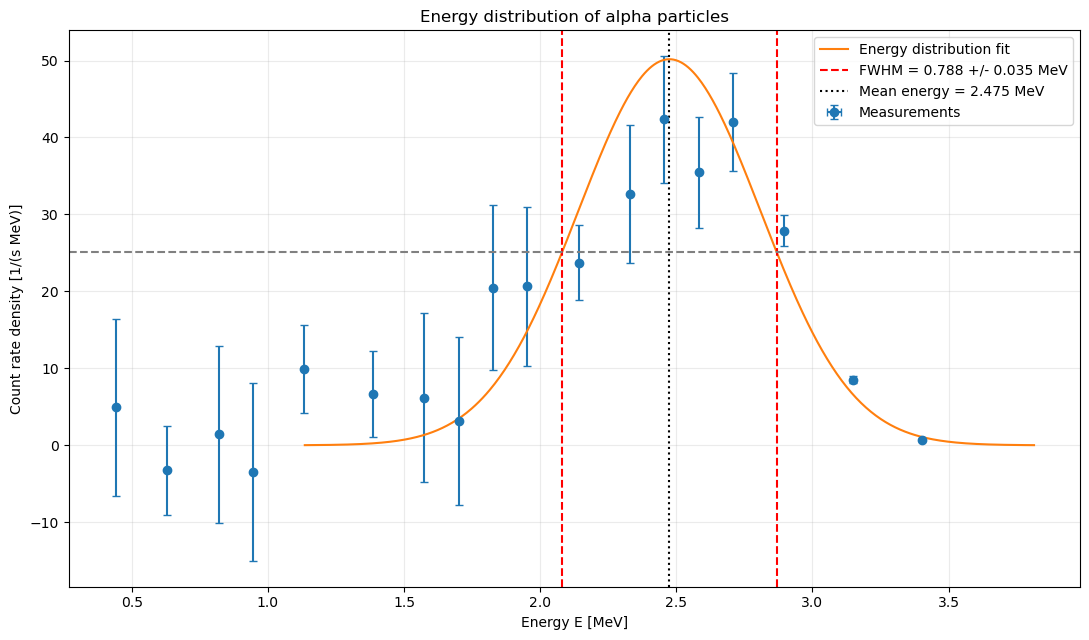

6.4 Exponent a = -4.061 +/- 0.186 (stat.), theory -4
    Reduced chi2 = 0.467, p = 0.912


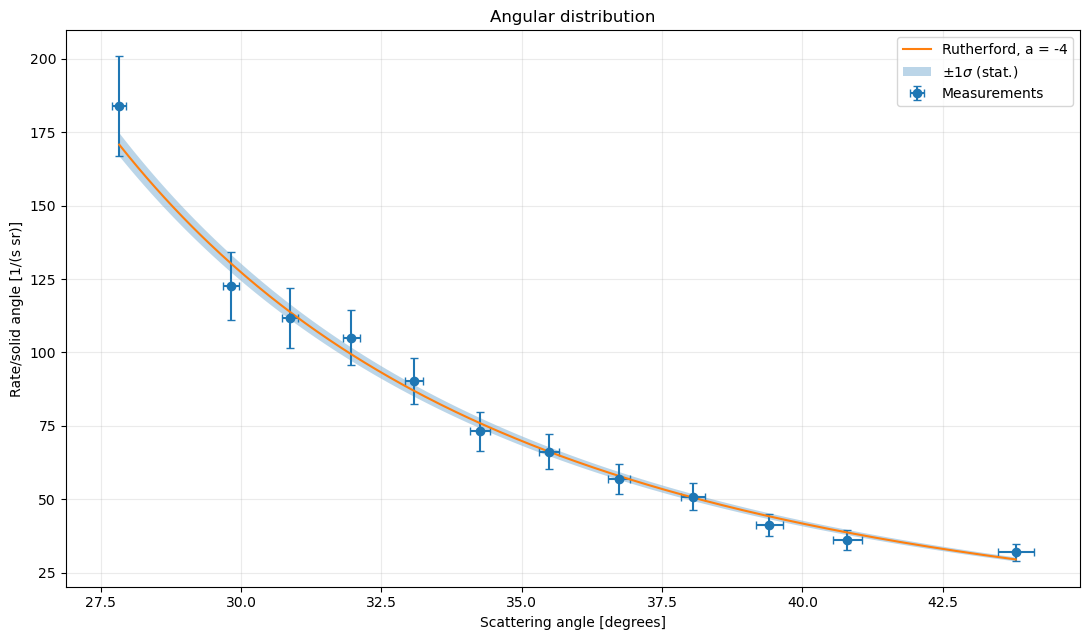

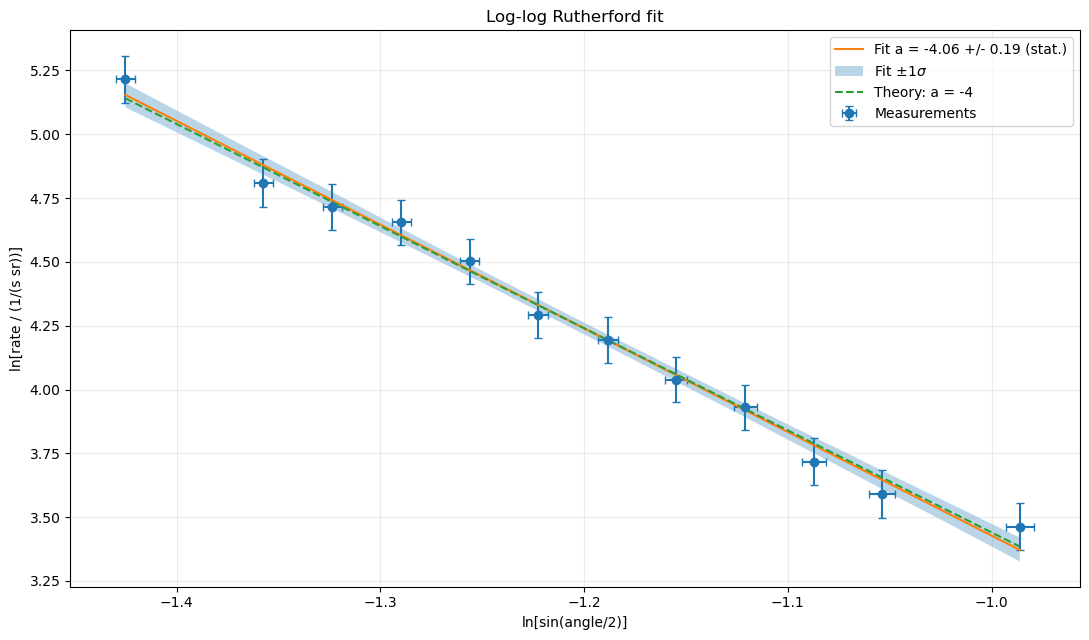

Initial energy before air path: 3.650 MeV
Air loss before scattering: 0.178 MeV
Gold loss before scattering: 0.281 MeV
Energy at foil midpoint: 3.191 MeV
Exponent: -4.061 +/- 0.187; 95% approx. [-4.428, -3.694]
Intercept: -0.633 +/- 0.230; fixed-slope intercept: -0.560 +/- 0.049
chi2/dof = 0.47; p = 0.912; dof = 10
95% chi2/dof acceptance interval: [0.32, 2.05]
Expected activity today: 3.658 MBq
Activity (Direct beam): 3.94 +/- 0.40 MBq; 1.065e-04 +/- 1.1e-05 Ci; +7.7 % vs. expected (0.71 sigma)
Activity (Scattering): 3.97 +/- 0.21 MBq; 1.072e-04 +/- 5.6e-06 Ci; +8.4 % vs. expected (1.47 sigma)


In [2]:
from pathlib import Path
from datetime import date
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares
from scipy.special import erfc
from scipy.stats import chi2

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# ===== 1. LAB INPUTS: ONLY EDIT THIS SECTION ====================
u = dict(x=0.5, delta=0.5, R1=0.05, R2=0.05, AD=2.0,
         offset=0.5, t=0.25, U=1.0, hole=0.05, foil=0.01,
         E=0.15, nAu=0.01*N_Au)

OFFSET = 3.0           
HOLE = 1.0             

# Air loss BEFORE scattering (20 mbar, from exercise 3.4.2)
AIR_PRESSURE_MBAR = 20.0
STOPPING_AIR_10MBAR = 1.1335e-3  # MeV/mm at 10 mbar

U_WORK = 150           # discriminator operating threshold
PLATEAU_START, PLATEAU_END = 125, 300   # plateau range [device units]
ERFC_FIT_START = 125   # start of erfc fit [device units]
U_ZERO, u_U_ZERO = 50, 0.05             # pulse-height zero point (None = not calibrated)

N_bg, t_bg = 53, 3600            # background, everything closed, 1 h
N_direct, t_direct = 22195, 500  # direct beam at U_WORK

SOURCE_DATE = date(2019, 9, 23)
SOURCE_ACTIVITY = 3.7e6   # Bq at SOURCE_DATE
HALF_LIFE = 432           # years (manual: 432 y)

# 185 mm distance, threshold uncertainty 3 mV
# Rows = [threshold, counts, time in s]
disc = np.array([
    [50, 34, 500], [100, 743, 45], [125, 2010, 45], [150, 1982, 45],
    [200, 2019, 45], [225, 2011, 45], [250, 2031, 45], [300, 1918, 45],
    [350, 1842, 45], [375, 1807, 45], [400, 1789, 45], [425, 1673, 45],
    [450, 1556, 45], [500, 1287, 45], [525, 1102, 45], [550, 862, 45],
    [575, 661, 45], [600, 423, 45], [650, 593, 250], [700, 56, 250],
    [750, 9, 250]], float)

# Rows = [x to DETECTOR FRONT (mm), counts, time in s]
ang = np.array([
    [50, 174, 400], [58.1, 160, 400], [62.6, 162, 400], [67.6, 177, 400],
    [73.1, 174, 400], [79.1, 178, 400], [85.9,171, 400], [93.4, 182 , 400],
    [101.8, 182, 400], [111.4, 165, 400], [122.4, 153, 400], [150.0, 157, 400]], float)


# ===== 2. HELPERS ===============================================
def rate(N, t):
    """Count rate with Poisson and timing uncertainty."""
    # [FEHLER 01] Zaehlrate r=N/t; Poisson-Statistik u_N~sqrt(N).
    #             u_r=sqrt[(u_N/t)^2+(N*u_t/t^2)^2].
    #             Der bestehende Code benutzt sqrt(N+1) statt sqrt(N).
    r = N/t
    return r, np.hypot(np.sqrt(N+1)/t, r*u['t']/t)

# [FEHLER 02] Allgemeine Gauss-Fehlerfortpflanzung fuer unabhaengige Eingaben:
#             u_f^2=sum_i [(df/dq_i)*u_q_i]^2; die Ableitungen sind numerisch.
def prop(f, *pairs):
    """Gaussian error propagation for independent inputs.
    pairs = (value, uncertainty); values may be arrays. Returns (f, u_f)."""
    vals = [np.asarray(v, float) for v, _ in pairs]
    f0, var = f(*vals), 0.0
    for i, (_, e) in enumerate(pairs):
        h = 1e-6*np.maximum(np.abs(vals[i]), 1)
        up, dn = vals.copy(), vals.copy()
        up[i], dn[i] = vals[i]+h, vals[i]-h
        var = var + ((f(*up) - f(*dn))/(2*h)*e)**2
    return f0, np.sqrt(var)

def theta(x, d=delta, r=RA):          # scattering angle [rad], point source
    return np.arctan(r/d) + np.arctan(r/x)

def omega_det(x, area=AD, r=RA):      # detector solid angle, eq. (42) [sr]
    return area*x/(x*x + r*r)**1.5

# [FEHLER 03] Unsicherheitsband im Plot: Stichproben der FIT-KOVARIANZ,
#             16./84. Perzentil (ungefaehr ein 1-sigma-Band).
def fit_band(f, p, cov, xx, n=1000):
    """1-sigma band of a fit curve from the parameter covariance."""
    s = np.random.default_rng(0).multivariate_normal(p, cov, n)
    return np.percentile([f(xx, *si) for si in s], [16, 84], axis=0)

def finish(fig, ax, name, title, xlabel, ylabel):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=.25)
    ax.legend(loc='best', fontsize=10)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / name, bbox_inches='tight')
    plt.show()

def figure():
    return plt.subplots(figsize=(11, 6.5))

EB = dict(fmt='o', capsize=3, label='Measurements')   # errorbar style

# ===== 3. COUNT RATES ===========================================
# ===== [FEHLER 04] ZAEHLSTATISTIK FUER ALLE MESSREIHEN =====
# Hintergrund, Diskriminator, Winkelmessung und Direktstrahl verwenden rate().
bg, ubg = rate(N_bg, t_bg)
U, Nd, td = disc[np.isfinite(disc[:, 1])].T
zd, uzd = rate(Nd, td)
xf, N, t = ang.T
z, uz = rate(N, t)
z_dir, uz_dir = rate(N_direct, t_direct)
print(f'6.3 Background = {bg:.5f} +/- {ubg:.5f} 1/s')


# ===== 6.2 DISCRIMINATOR CURVE AND PULSE-HEIGHT SPECTRUM ========
def erf_curve(U, A, B, C):
    return bg + A*erfc((U - B)/(np.sqrt(2)*C))

def gauss(U, A, B, C):                # -d/dU of erf_curve
    return 2*A/(np.sqrt(2*np.pi)*C)*np.exp(-(U - B)**2/(2*C*C))

m = U >= ERFC_FIT_START
Uf, zf, uzf = U[m], zd[m], uzd[m]

p, cov = curve_fit(erf_curve, Uf, zf, sigma=uzf, absolute_sigma=True,
                   p0=[zf.max()/2, np.median(Uf), np.ptp(Uf)/5],
                   bounds=([0, Uf.min(), 1e-3], [np.inf, Uf.max(), np.inf]))
A_erf, B, C = p
uB, uC = np.sqrt(np.diag(cov))[1:]
# [FEHLER 07] FWHM=2*sqrt(2*ln2)*C und u_FWHM=2*sqrt(2*ln2)*u_C.
K_FWHM = 2*np.sqrt(2*np.log(2))
print(f'\n6.2 Peak B = {B:.3f} +/- {uB:.3f} threshold units; '
      f'FWHM = {K_FWHM*C:.3f} +/- {K_FWHM*uC:.3f} threshold units')

# Plateau: weighted straight line
pl = (U >= PLATEAU_START) & (U <= PLATEAU_END)
(slope, icpt), pcov = np.polyfit(U[pl], zd[pl], 1, w=1/uzd[pl], cov='unscaled')
uslope = np.sqrt(pcov[0, 0])
print(f'    Plateau [{PLATEAU_START}, {PLATEAU_END}]: slope = {slope:+.3f} +/- '
      f'{uslope:.3f} 1/(s unit) ({pl.sum()} points)')

Um, dU = (Uf[1:] + Uf[:-1])/2, np.diff(Uf)
spec = -np.diff(zf)/dU
uspec = np.sqrt(uzf[:-1]**2 + uzf[1:]**2 + 2*(spec*u['U'])**2)/dU
UU = np.linspace(ERFC_FIT_START, Uf.max(), 300)

# Plot 1: discriminator curve
fig, ax = figure()
ax.errorbar(U, zd, xerr=u['U'], yerr=uzd, **EB)
ax.plot(UU, erf_curve(UU, *p), label='Erfc fit')
ax.fill_between(UU, *fit_band(erf_curve, p, cov, UU), alpha=.3, label=r'Fit $\pm1\sigma$')
ax.axvspan(PLATEAU_START, PLATEAU_END, color='red', alpha=.09)
UP = np.array([PLATEAU_START, PLATEAU_END])
ax.plot(UP, slope*UP + icpt, color='red', lw=2.2,label=f'Plateau slope = {slope:+.3f} +/- {uslope:.3f} 1/(s unit)')
ax.axvline(U_WORK, color='0.5', ls='--', label='Operating threshold')
finish(fig, ax, 'rutherford_discriminator.pdf', 'Discriminator curve','Threshold [device units]', 'Count rate [1/s]')

# Plot 2: pulse-height spectrum
fig, ax = figure()
ax.errorbar(Um, spec, xerr=u['U']/np.sqrt(2), yerr=uspec, **EB)
ax.plot(UU, gauss(UU, *p), label='Derivative of erfc fit')
ax.fill_between(UU, *fit_band(gauss, p, cov, UU), alpha=.3, label=r'Fit $\pm1\sigma$')
finish(fig, ax, 'rutherford_pulse_height.pdf', 'Pulse-height spectrum','Threshold [device units]', 'Pulse-height density [1/(s unit)]')


# ===== ENERGY CALIBRATION AND FWHM =========================

L_source_foil = 185.0
L_foil_detector = 74.5
P_air = 20.0
L_air = L_source_foil + L_foil_detector
dE_air = STOPPING_AIR_10MBAR * (P_air / 10.0) * L_air
dE_gold = S_Au * d_foil / 1000
dE_window = S_Au * d_window / 1000
E_DET = E0 - dE_air - dE_gold - dE_window

z_direct = N_direct / t_direct
uz_direct = np.hypot(
    np.sqrt(N_direct + 1) / t_direct,
    z_direct * u["t"] / t_direct
)

print("\n=== DIRECT DETECTOR ENERGY ===")
print(f"Air energy loss: {dE_air:.4f} MeV")
print(f"Gold foil energy loss: {dE_gold:.4f} MeV")
print(f"Detector window loss: {dE_window:.4f} MeV")
print(f"Energy at detector: {E_DET:.4f} MeV")
print(f"Direct count rate: {z_direct:.3f} +/- {uz_direct:.3f} 1/s")

# ===== ENERGY CALIBRATION ==================================

kE = E_DET / (B - U_ZERO)
sE = kE * C
fwhm_E = K_FWHM * kE * C

# Covariance propagation
g = np.array([0,-1 / (B - U_ZERO),1 / C])
rel = np.sqrt(g @ cov @ g+ (u["E"] / E0)**2+ (u_U_ZERO / (B - U_ZERO))**2)
ufwhm_E = fwhm_E * rel

print("\n=== ENERGY DISTRIBUTION ===")
print(f"Conversion factor: {kE:.4f} MeV/mV")
print(f"Sigma_E: {sE:.4f} MeV")
print(f"FWHM: {fwhm_E:.4f} +/- {ufwhm_E:.4f} MeV")


# Plot 3: energy distribution (measured points + fit, per MeV)
EE = np.linspace(E_DET - 4*sE, E_DET + 4*sE, 600)
yE = gauss(EE, A_erf, E_DET, sE)
fig, ax = figure()
ax.errorbar(kE*(Um - U_ZERO), spec/kE, xerr=kE*u['U']/np.sqrt(2), yerr=uspec/kE, **EB)
ax.plot(EE, yE, label='Energy distribution fit')
for e in (E_DET - fwhm_E/2, E_DET + fwhm_E/2):
    ax.axvline(e, color='red', ls='--')
ax.lines[-1].set_label(f'FWHM = {fwhm_E:.3f} +/- {ufwhm_E:.3f} MeV')
ax.axhline(yE.max()/2, color='gray', ls='--')
ax.axvline(E_DET, color='black', ls=':', label=f'Mean energy = {E_DET:.3f} MeV')
finish(fig, ax, 'rutherford_energy_distribution.pdf','Energy distribution of alpha particles', 'Energy E [MeV]', 'Count rate density [1/(s MeV)]')


# ===== 6.3 / 6.4 ANGULAR DISTRIBUTION ===========================
x = xf + OFFSET                   # mandatory +3 mm to sensitive surface
net = z - bg

uR = np.hypot(u['R1'], u['R2'])/2          # RA = (R1+R2)/2
ux = np.hypot(u['x'], u['offset'])
th, uth = prop(theta, (x, ux), (delta, u['delta']), (RA, uR))
Om, uOm = prop(omega_det, (x, ux), (AD, u['AD']), (RA, uR))
I = net/Om                                   # [1/(s sr)]

uI = np.hypot(np.hypot(uz, ubg)/Om, I*uOm/Om)
X, uX = prop(lambda a: np.log(np.sin(a/2)), (th, uth))
Y, uY = np.log(I), uI/I


def fit(d=delta, r=RA, area=AD, off=OFFSET, back=bg):
    """Fit Y = aX + b with errors in x and y (eq. 50, x-correlation included),
    plus fit with fixed slope -4. Returns a, b, b4, ua, ub, ub4, chi2, cov."""
    xs, net = xf + off, z - back
    Xf = lambda x: np.log(np.sin(theta(x, d, r)/2))
    Yf = lambda x: np.log(net/omega_det(x, area, r))
    X0, Y0 = Xf(xs), Yf(xs)
    h = 1e-4
    dX, dY = [(f(xs + h) - f(xs - h))/(2*h) for f in (Xf, Yf)]
    sig = lambda a: np.hypot(uz/net, (dY - a*dX)*u['x'])
    res = least_squares(lambda q: (Y0 - q[0]*X0 - q[1])/sig(q[0]),
                        x0=[-4, np.median(Y0 + 4*X0)])
    cov = np.linalg.pinv(res.jac.T @ res.jac)
    w = 1/sig(-4)**2
    b4 = np.average(Y0 + 4*X0, weights=w)
    return (*res.x, b4, *np.sqrt(np.diag(cov)), 1/np.sqrt(w.sum()),np.sum(res.fun**2), cov)


a, b, b4, ua_stat, ub_stat, ub4_stat, chisq, cov_ab = fit()
dof = len(ang) - 2
print(f'6.4 Exponent a = {a:.3f} +/- {ua_stat:.3f} (stat.), theory -4')
print(f'    Reduced chi2 = {chisq/dof:.3f}, p = {chi2.sf(chisq, dof):.3f}')

# Plot 4: angular distribution
TT = np.linspace(th.min(), th.max(), 300)
ruth = lambda T, b: np.exp(b)/np.sin(T/2)**4
fig, ax = figure()
ax.errorbar(np.degrees(th), I, xerr=np.degrees(uth), yerr=uI, **EB)
ax.plot(np.degrees(TT), ruth(TT, b4), label='Rutherford, a = -4')
ax.fill_between(np.degrees(TT), ruth(TT, b4 - ub4_stat), ruth(TT, b4 + ub4_stat),alpha=.3, label=r'$\pm1\sigma$ (stat.)')
finish(fig, ax, 'rutherford_angular_distribution.pdf', 'Angular distribution','Scattering angle [degrees]', 'Rate/solid angle [1/(s sr)]')

# Plot 5: log-log fit
XX = np.linspace(X.min(), X.max(), 300)
line = lambda X, a, b: a*X + b
fig, ax = figure()
ax.errorbar(X, Y, xerr=uX, yerr=uY, **EB)
ax.plot(XX, line(XX, a, b), label=f'Fit a = {a:.2f} +/- {ua_stat:.2f} (stat.)')
ax.fill_between(XX, *fit_band(line, [a, b], cov_ab, XX), alpha=.3, label=r'Fit $\pm1\sigma$')
ax.plot(XX, line(XX, -4, b4), ls='--', label='Theory: a = -4')
finish(fig, ax, 'rutherford_fit.pdf', 'Log-log Rutherford fit','ln[sin(angle/2)]', 'ln[rate / (1/(s sr))]')

# ===== 6.5 ACTIVITY (BOTH METHODS) ==============================
N_Au = 5.91e28  # atoms/m³

def activity(d, r1, r2, hole, E, foil, nat, b4, back):
    omega_F = 2 * np.pi * (d / np.hypot(d, r1)- d / np.hypot(d, r2))
    omega_H = 2 * np.pi * (1 - d / np.hypot(d, hole / 2))
    cross0 = (Z1 * Z2 * xi2 * 1e-9 / (4 * E * 1e6))**2
    Ad = (z_dir - back) * 4 * np.pi / omega_H
    As = np.exp(b4) / (nat * foil * 1e-6 * (omega_F / (4 * np.pi)) * cross0)
    return Ad, As

p = np.array([delta, R1, R2, AD, OFFSET, bg,1.0, d_foil, N_Au, HOLE], dtype=float)
up = np.array([u["delta"], u["R1"], u["R2"], u["AD"],u["offset"], ubg, u["E"] / E0, u["foil"],0.01 * N_Au, u["hole"]], dtype=float)

def stopping_power_gold(E, nat):
    epsilon = (3.80 / E) * Z2 * np.log(548.58 * E / 1059.81 + 1.037)
    return epsilon * nat * 1e-31



def calculate(p):
    d, r1, r2, area, off, back, e_scale, foil, nat, hole = p
    E_initial = E0
    r = (r1 + r2) / 2
    air_path = np.hypot(d, r)
    delta_E_air = (STOPPING_AIR_10MBAR * (AIR_PRESSURE_MBAR / 10.0) * air_path)
    E_at_foil = E_initial - delta_E_air
    half_path = (foil / 2) * air_path / d
    delta_E_gold = stopping_power_gold(E_at_foil, nat) * half_path
    E_mid = E_at_foil - delta_E_gold
    a, b, b4, ua, ub, ub4, chisq, cov = fit(d, r, area, off, back)
    Ad, As = activity(d, r1, r2, hole, E_mid, foil, nat, b4, back)

    return np.array([a, b, b4, Ad, As]), (ua, ub, ub4, chisq, cov)


# ===== NOMINAL RESULTS AND STATISTICAL FIT UNCERTAINTIES =====

results, fit_stats = calculate(p)
a, b, b4, Ad, As = results
ua_stat, ub_stat, ub4_stat, chisq, cov_ab = fit_stats
dof = len(ang) - 2



# ===== ERROR PROPAGATION OF INPUT PARAMETERS ================

u_params_sq = np.zeros(5, dtype=float)

for j, step in enumerate(up):
    p_plus = p.copy()
    p_minus = p.copy()
    p_plus[j] += step
    p_minus[j] -= step
    result_plus, x = calculate(p_plus)
    result_minus, y = calculate(p_minus)
    delta_result = (result_plus - result_minus) / 2
    u_params_sq += delta_result**2

u_params = np.sqrt(u_params_sq)


# ===== STATISTICAL ACTIVITY UNCERTAINTIES ===================
u_zdir = np.hypot(np.sqrt(N_direct) / t_direct,(N_direct / t_direct) * u["t"] / t_direct)
omega_H_nom = 2 * np.pi * (1 - delta / np.hypot(delta, HOLE / 2))
uAd_stat = u_zdir * 4 * np.pi / omega_H_nom
uAs_stat = As * ub4_stat


# ===== TOTAL UNCERTAINTIES ==================================

ua = np.hypot(ua_stat, u_params[0])
ub = np.hypot(ub_stat, u_params[1])
ub4 = np.hypot(ub4_stat, u_params[2])
uAd = np.hypot(uAd_stat, u_params[3])
uAs = np.hypot(uAs_stat, u_params[4])

# ===== ENERGY AT THE GOLD FOIL MIDPOINT =====================
air_path = np.hypot(delta, RA)
delta_E_air = (STOPPING_AIR_10MBAR * (AIR_PRESSURE_MBAR / 10.0) * air_path)
E_at_foil = E0 - delta_E_air

half_path = (d_foil / 2) * air_path / delta
delta_E_gold = ( stopping_power_gold(E_at_foil, N_Au) * half_path)
E_mid = E_at_foil - delta_E_gold

print(f"Initial energy before air path: {E0:.3f} MeV")
print(f"Air loss before scattering: {delta_E_air:.3f} MeV")
print(f"Gold loss before scattering: {delta_E_gold:.3f} MeV")
print(f"Energy at foil midpoint: {E_mid:.3f} MeV")


# ===== EXPECTED SOURCE ACTIVITY =============================

elapsed_years = (date.today() - SOURCE_DATE).days / 365.25
A_exp = SOURCE_ACTIVITY * 2**(-elapsed_years / HALF_LIFE)

# ===== SUMMARY ==============================================

print(f'Exponent: {a:.3f} +/- {ua:.3f}; 'f'95% approx. [{a - 1.96*ua:.3f}, {a + 1.96*ua:.3f}]')
print(f'Intercept: {b:.3f} +/- {ub:.3f}; 'f'fixed-slope intercept: {b4:.3f} +/- {ub4:.3f}')
print(f'chi2/dof = {chisq/dof:.2f}; 'f'p = {chi2.sf(chisq, dof):.3f}; dof = {dof}')
print(f'95% chi2/dof acceptance interval: 'f'[{chi2.ppf(.025, dof)/dof:.2f}, 'f'{chi2.ppf(.975, dof)/dof:.2f}]')
print(f'Expected activity today: {A_exp/1e6:.3f} MBq')

for label, val, err in [('Direct beam', Ad, uAd),('Scattering', As, uAs)]:
    print(f'Activity ({label}): 'f'{val/1e6:.2f} +/- {err/1e6:.2f} MBq; 'f'{val/3.7e10:.3e} +/- {err/3.7e10:.1e} Ci; 'f'{(val/A_exp - 1)*100:+.1f} % vs. expected 'f'({abs(val - A_exp)/err:.2f} sigma)' )



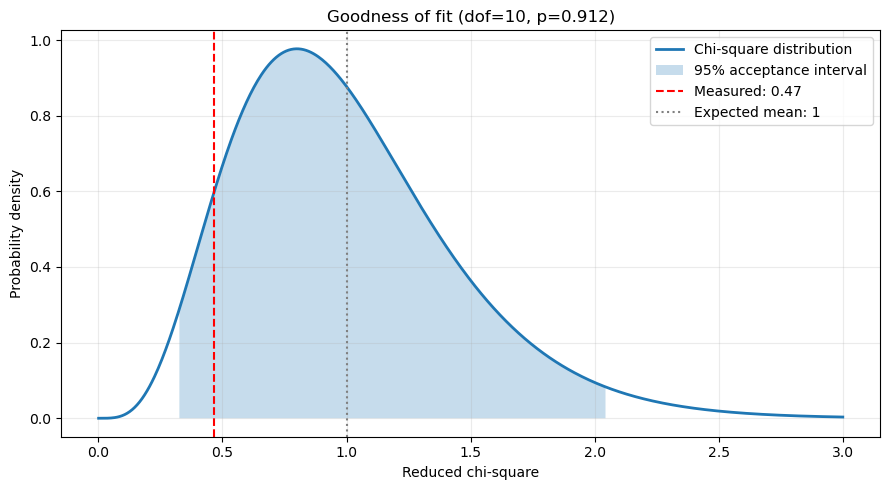

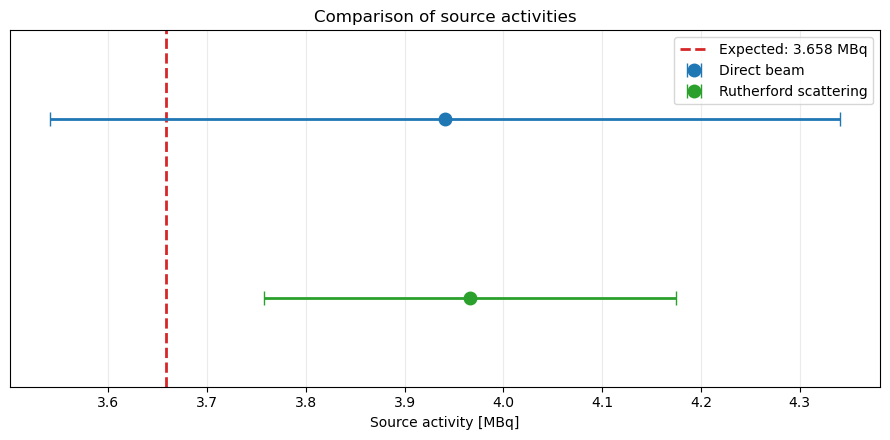

In [3]:
 
# ===== RESULTS VISUALIZATION ==============================
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

# 1. Reduced chi-square distribution
chi_red = chisq / dof
low, high = chi2.ppf([0.025, 0.975], dof) / dof
x = np.linspace(0.001, 3, 600)
y = dof * chi2.pdf(dof*x, dof)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, y, lw=2, label="Chi-square distribution")
ax.fill_between(x, y, where=(x >= low) & (x <= high),alpha=0.25, label="95% acceptance interval")
ax.axvline(chi_red, color="red", ls="--",label=f"Measured: {chi_red:.2f}")
ax.axvline(1, color="gray", ls=":", label="Expected mean: 1")
ax.set(xlabel="Reduced chi-square", ylabel="Probability density",title=f"Goodness of fit (dof={dof}, p={chi2.sf(chisq,dof):.3f})")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "rutherford_chi_squared.pdf", bbox_inches="tight")
plt.show()


# 2. Activity comparison
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvline(A_exp/1e6, color="tab:red", ls="--", lw=2,label=f"Expected: {A_exp/1e6:.3f} MBq", zorder=1)
ax.errorbar(Ad/1e6, 1, xerr=uAd/1e6,fmt="o", color="tab:blue",markersize=9, capsize=5, lw=2,label="Direct beam", zorder=3)
ax.errorbar(As/1e6, 0, xerr= uAs/1e6,fmt="o", color="tab:green",markersize=9, capsize=5, lw=2,label="Rutherford scattering", zorder=3)
ax.set(xlabel="Source activity [MBq]",title="Comparison of source activities",ylim=(-0.5, 1.5))
ax.set_yticks([])
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "rutherford_activity_comparison.pdf",bbox_inches="tight")
plt.show()